In [1]:
!pip install tensorflow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.metrics import MeanAbsoluteError
from tensorflow.keras.optimizers import Adam

In [2]:
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

#Load the data
df = pd.read_csv("international-airline-passengers.csv")
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")
df.head()

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


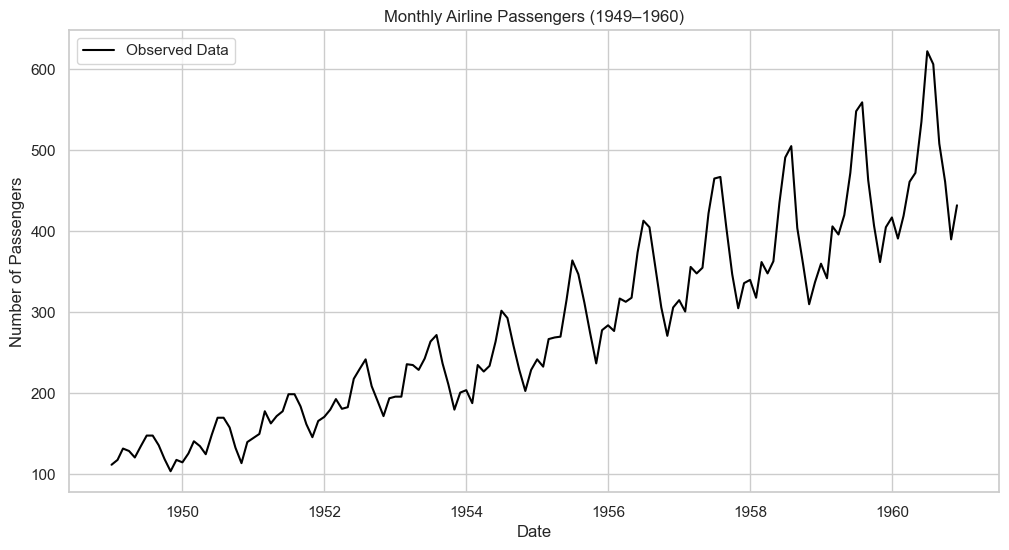

In [3]:
#Plot the data
plt.plot(df.index, df["Passengers"], label="Observed Data", color="black")
plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.legend()
plt.show()

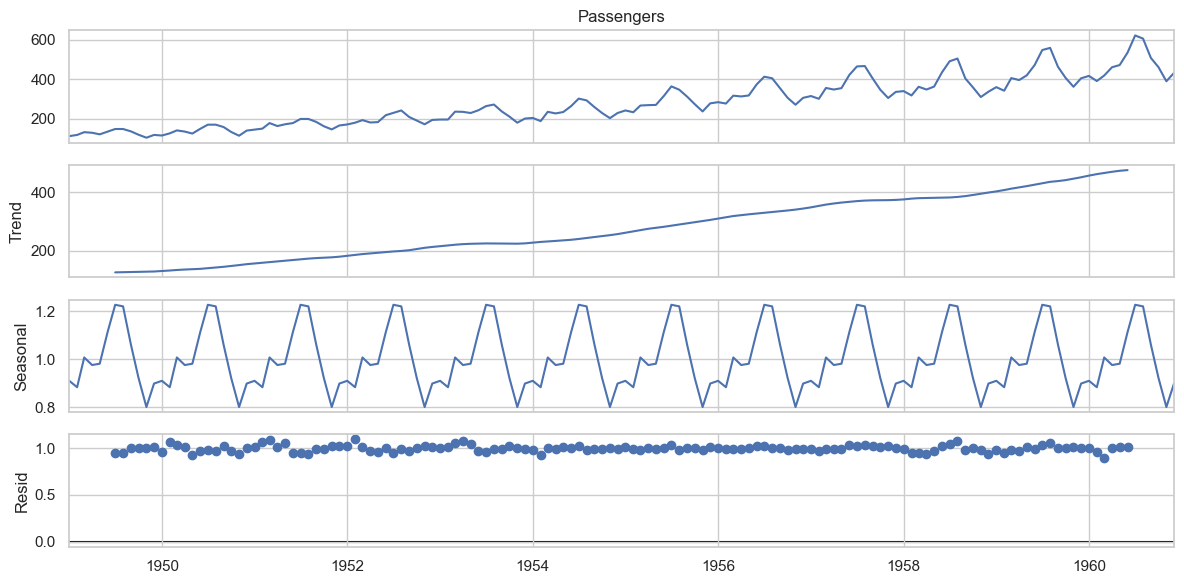

In [4]:
#Decompose the data
result = seasonal_decompose(df["Passengers"], model="multiplicative", period=12)
result.plot()
plt.show()

## Baseline Model

In [5]:
#split to train and test
train = df.iloc[:-12]
test = df.iloc[-12:]

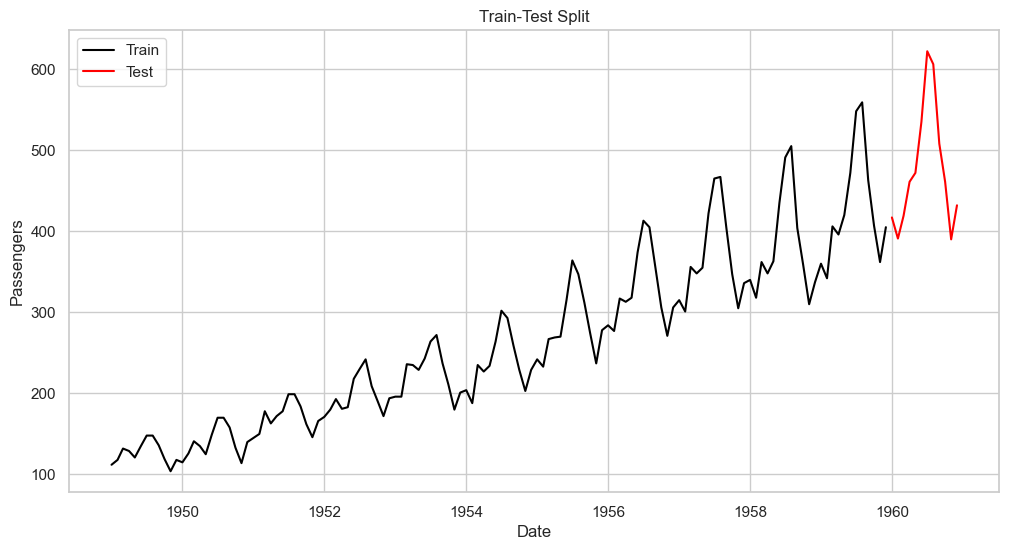

In [6]:
#print the split
plt.plot(train.index, train["Passengers"], label="Train", color="black")
plt.plot(test.index, test["Passengers"], label="Test", color="red")
plt.title("Train-Test Split")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.show()

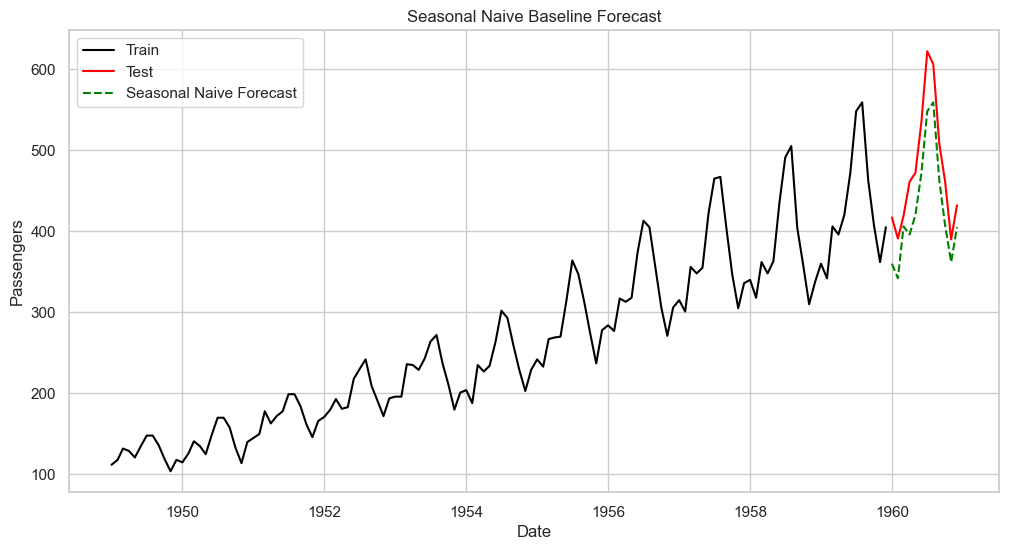

In [7]:
#Seasonal naive model
seasonal_naive = pd.Series(train["Passengers"].iloc[-12:].values, index=test.index)

plt.figure(figsize=(12, 6))
plt.plot(train.index, train["Passengers"], label="Train", color="black")
plt.plot(test.index, test["Passengers"], label="Test", color="red")
plt.plot(test.index, seasonal_naive, label="Seasonal Naive Forecast", color="green", linestyle="--")
plt.title("Seasonal Naive Baseline Forecast")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.show()

## Statistical Model

# Holt-Winters Model

In [8]:
fit_add = ExponentialSmoothing(
    train["Passengers"],
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit()
fcast_add = fit_add.forecast(12)

fit_mul = ExponentialSmoothing(
    train["Passengers"],
    trend='add',
    seasonal='mul',
    seasonal_periods=12
).fit()
fcast_mul = fit_mul.forecast(12)

C:\Users\moham\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\moham\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


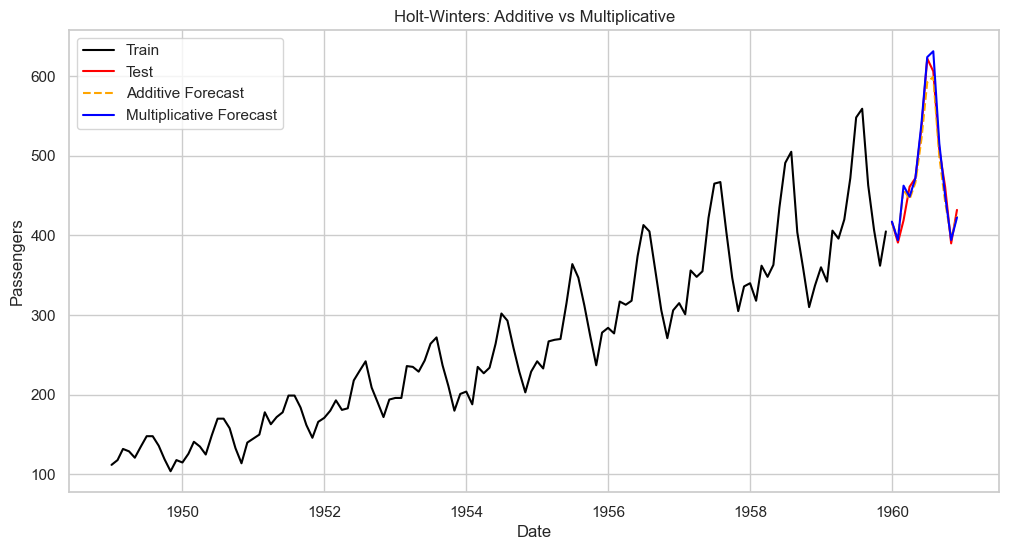

In [9]:
#Plot
plt.figure(figsize=(12, 6))
plt.plot(train.index, train["Passengers"], label='Train', color='black')
plt.plot(test.index, test["Passengers"], label='Test', color='red')
plt.plot(test.index, fcast_add, label='Additive Forecast', color='orange', linestyle='--')
plt.plot(test.index, fcast_mul, label='Multiplicative Forecast', color='blue')
plt.title("Holt-Winters: Additive vs Multiplicative")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.show()

In [10]:
#Mean absolute and Root mean squared error
forecast = fit_mul.forecast(12)
errors = test["Passengers"] - forecast

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors**2))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 10.303248668883532
RMSE: 15.810478481502829


In [11]:
hw_errors = test["Passengers"] - forecast
snaive_errors = test["Passengers"] - seasonal_naive

hw_rmse = np.sqrt(np.mean(hw_errors**2))
snaive_rmse = np.sqrt(np.mean(snaive_errors**2))

print("Holt-Winters RMSE:", hw_rmse)
print("Seasonal Naive RMSE:", snaive_rmse)

if hw_rmse < snaive_rmse:
    print("Holt-Winters performs better than the seasonal naive forecast.")
else:
    print("Seasonal naive performs better than Holt-Winters.")

Holt-Winters RMSE: 15.810478481502829
Seasonal Naive RMSE: 50.708316214732804
Holt-Winters performs better than the seasonal naive forecast.


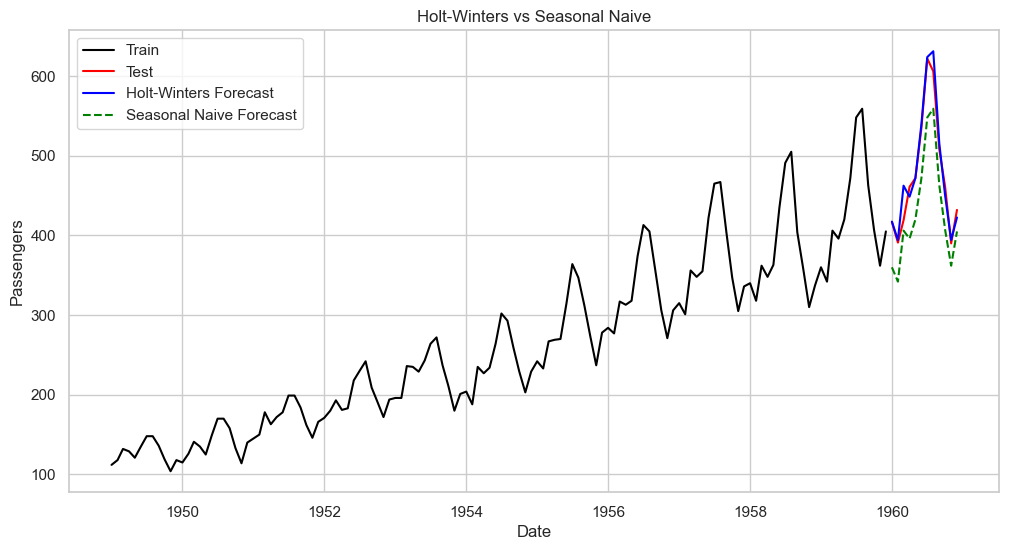

In [12]:
plt.figure(figsize=(12, 6))
plt.plot(train.index, train["Passengers"], label="Train", color="black")
plt.plot(test.index, test["Passengers"], label="Test", color="red")
plt.plot(test.index, forecast, label="Holt-Winters Forecast", color="blue")
plt.plot(test.index, seasonal_naive, label="Seasonal Naive Forecast", color="green", linestyle="--")
plt.title("Holt-Winters vs Seasonal Naive")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.show()

## Deep Learning Model

In [13]:
#Load data again
df = pd.read_csv("international-airline-passengers.csv")
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")
df.head()

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [14]:
#Split the data into training, validation and testing
train_df = df.iloc[:-48]
val_df = df.iloc[-48:-24]
test_df = df.iloc[-24:]

In [15]:
#compute mean and std from training data
train_mean = train_df.mean()
train_std = train_df.std()

#standardise the splits
train_df = (train_df - train_mean) / train_std
val_df = (val_df - train_mean) / train_std
test_df = (test_df - train_mean) / train_std

In [16]:
#define a class to handle time-series windowing and dataset creation
class DataWindow():
#Initialize the class with window parameters and data splits
    def __init__(self, input_width, label_width, shift, train_df = train_df, val_df = val_df,
                test_df = test_df, label_columns = None):
        
        self.train_df = train_df
        self.val_df = val_df
        self.test_df = test_df

        self.label_columns = label_columns
        if label_columns is not None:
            self.label_columns_indices = {name: i for i, name in enumerate(label_columns)}
        self.column_indices = {name: i for i, name in enumerate(train_df.columns)}

        self.input_width = input_width
        self.label_width = label_width
        self.shift = shift

        self.total_window_size = input_width + shift

        self.input_slice = slice(0, input_width)
        self.input_indices = np.arange(self.total_window_size)[self.input_slice]

        self.label_start = self.total_window_size - self.label_width
        self.labels_slice = slice(self.label_start, None)
        self.label_indices = np.arange(self.total_window_size)[self.labels_slice]

#Split the window of data into inputs and labels
    def split_to_inputs_labels(self, features):
        inputs = features[:, self.input_slice, :]
        labels = features[:, self.labels_slice, :]

        if self.label_columns is not None:
            labels = tf.stack(
                [labels[:, :, self.column_indices[name]] for name in self.label_columns],
                axis = -1)
            
        inputs.set_shape([None, self.input_width, None])
        labels.set_shape([None, self.label_width, None])

        return inputs, labels

#Visualize inputs, labels and model predictions
    def plot(self, model = None, plot_col = 'Passengers', max_subplots = 3):
        inputs, labels = self.sample_batch

        plt.figure(figsize = (12,8))
        plot_col_index = self.column_indices[plot_col]
        max_n = min(max_subplots, len(inputs))

        for n in range(max_n):
            plt.subplot(max_n, 1, n + 1)
            plt.ylabel(f'{plot_col}')

            plt.plot(self.input_indices, inputs[n, :, plot_col_index],
                     label = 'Inputs', marker = '.', zorder = -10)
            if self.label_columns:
                label_col_index = self.label_columns_indices.get(plot_col, None)
            else:
                label_col_index = plot_col_index

            if label_col_index is None:
                continue

            plt.scatter(self.label_indices, labels[n, :, label_col_index],
                        edgecolors = 'k', label = 'Labels', c = 'green', s = 64)

            if model is not None:
                predictions = model(inputs)
                plt.scatter(self.label_indices, labels[n, :, label_col_index],
                            marker = 'X', edgecolors = 'k', label = 'Predictions', c = 'orange', s = 64)

            if n == 0:
                plt.legend()

        plt.xlabel('Time step')
        plt.tight_layout()
        

#Convert a raw pandas dataframe into a TensorFlow dataset
    def make_dataset(self, data):
        data = np.array(data, dtype = np.float32)

        ds = tf.keras.preprocessing.timeseries_dataset_from_array(
            data = data, 
            targets = None,
            sequence_length = self.total_window_size,
            sequence_stride = 1,
            shuffle = True,
            batch_size = 32
        )

        ds = ds.map(self.split_to_inputs_labels)
        return ds

#@property to change how to interact with the data
    @property
    def train(self):
        return self.make_dataset(self.train_df)

    @property
    def val(self):
        return self.make_dataset(self.val_df)

    @property
    def test(self):
        return self.make_dataset(self.test_df)

    @property
    def sample_batch(self):
        result = getattr(self, '_sample_batch', None)
        if result is None:
            result = next(iter(self.train))
            self._sample_batch = result
        return result

In [17]:
#Compile and train any given model using our data windows
def compile_and_fit(model, window, patience = 5, max_epochs = 100):

    early_stopping = EarlyStopping(
        monitor = 'val_loss',
        patience = patience,
        mode = 'min'
    )

    model.compile(
        loss = MeanSquaredError(),
        optimizer = Adam(),
        metrics = [MeanAbsoluteError()]
    )

    history = model.fit(
        window.train,
        epochs = max_epochs,
        validation_data = window.val,
        callbacks = [early_stopping]
    )

    return history     

In [18]:
#Define the window
wide_window = DataWindow(
    input_width = 12,
    label_width = 12,
    shift = 12,
    label_columns = ['Passengers']
)

In [19]:
#Building LSTM model
lstm_model = Sequential([LSTM(32, return_sequences = True),
                         Dense(units = 1)])
history = compile_and_fit(lstm_model, wide_window)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 468ms/step - loss: 0.6223 - mean_absolute_error: 0.6183 - val_loss: 4.7834 - val_mean_absolute_error: 2.0359
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - loss: 0.5792 - mean_absolute_error: 0.5931 - val_loss: 4.4017 - val_mean_absolute_error: 1.9428
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - loss: 0.5417 - mean_absolute_error: 0.5699 - val_loss: 4.0365 - val_mean_absolute_error: 1.8486
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step - loss: 0.5062 - mean_absolute_error: 0.5477 - val_loss: 3.6928 - val_mean_absolute_error: 1.7543
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - loss: 0.4721 - mean_absolute_error: 0.5256 - val_loss: 3.3554 - val_mean_absolute_error: 1.6556
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - loss: 0.4415 - mean_absolute_error: 0.5060 - val_loss: 3.0190 - val_mean_absolute_error: 1.5494
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - loss: 0.4124 - mean_absolute_error: 0.4885 - val_loss:

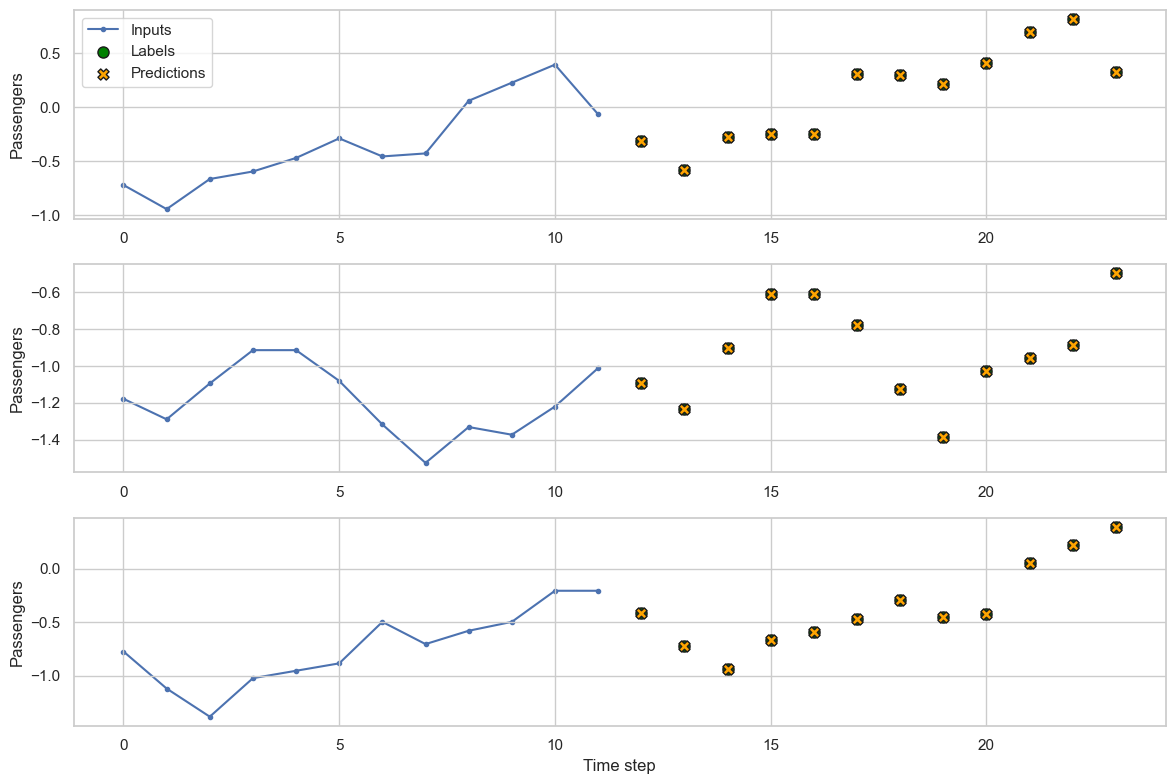

In [20]:
#plot the LSTM
wide_window.plot(lstm_model, plot_col = 'Passengers')

In [21]:
# Initialize empty dictionaries to store the evaluation metrics
val_performance = {}
performance = {}

val_performance['LSTM'] = lstm_model.evaluate(wide_window.val)
performance['LSTM'] = lstm_model.evaluate(wide_window.test, verbose = 0)

print("Validation performance:", val_performance['LSTM'])
print("Test performance:", performance['LSTM'])
print("LSTM validation MAE:", val_performance['LSTM'][1])
print("LSTM test MAE:", performance['LSTM'][1])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.2417 - mean_absolute_error: 0.4126
Validation performance: [0.24166138470172882, 0.412562757730484]
Test performance: [0.5761834979057312, 0.5466954112052917]
LSTM validation MAE: 0.412562757730484
LSTM test MAE: 0.5466954112052917


In [22]:
#Calculate RMSE of LSTM model
for inputs, labels in wide_window.test.take(1):
    predictions = lstm_model(inputs)

labels = labels.numpy()
predictions = predictions.numpy()
mean = train_mean["Passengers"]
std = train_std["Passengers"]

labels_original = labels[0, :, 0] * std + mean
predictions_original = predictions[0, :, 0] * std + mean

lstm_rmse = np.sqrt(np.mean((labels_original - predictions_original) ** 2))
print("LSTM RMSE:", lstm_rmse)

LSTM RMSE: 54.59077991803679


In [24]:
#compare RMSE of all modes
rmse_results = pd.DataFrame({
    "Model": ["Seasonal Naive", "Holt-Winters", "LSTM"],
    "RMSE": [snaive_rmse, hw_rmse, lstm_rmse]
})

rmse_results = rmse_results.sort_values("RMSE")
rmse_results

,Model,RMSE
1,Holt-Winters,15.810478
0,Seasonal Naive,50.708316
2,LSTM,54.590780
